In [1]:
from pathlib import Path

klasor = Path("../data/covid19_radiography/COVID-19_Radiography_Dataset/COVID/images")
dosyalar = list(klasor.glob("*.png"))
print(len(dosyalar))

3616


In [2]:
klasor = Path("../data/covid19_radiography/COVID-19_Radiography_Dataset/Lung_Opacity/images")
dosyalar = list(klasor.glob("*.png"))
print(len(dosyalar))

6012


In [3]:
klasor = Path("../data/covid19_radiography/COVID-19_Radiography_Dataset/Normal/images")
dosyalar = list(klasor.glob("*.png"))
print(len(dosyalar))

10192


In [4]:
klasor = Path("../data/covid19_radiography/COVID-19_Radiography_Dataset/Viral Pneumonia/images")
dosyalar = list(klasor.glob("*.png"))
print(len(dosyalar))

1345


In [5]:
from pathlib import Path

klasor = Path("../data/chest_xray/chest_xray/train/NORMAL")
dosyalar = list(klasor.glob("*.jpeg"))
print(len(dosyalar))

1341


In [6]:
klasor = Path("../data/chest_xray/chest_xray/train/PNEUMONIA")
dosyalar = list(klasor.glob("*.jpeg"))
print(len(dosyalar))

3875


In [7]:
klasor = Path("../data/chest_xray/chest_xray/test/NORMAL")
dosyalar = list(klasor.glob("*.jpeg"))
print(len(dosyalar))

234


In [8]:
klasor = Path("../data/chest_xray/chest_xray/test/PNEUMONIA")
dosyalar = list(klasor.glob("*.jpeg"))
print(len(dosyalar))

390


In [9]:
klasor = Path("../data/chest_xray/chest_xray/val/NORMAL")
dosyalar = list(klasor.glob("*.jpeg"))
print(len(dosyalar))

8


In [10]:
klasor = Path("../data/chest_xray/chest_xray/val/PNEUMONIA")
dosyalar = list(klasor.glob("*.jpeg"))
print(len(dosyalar))

8


In [11]:
import pandas as pd

ana = Path("../data/covid19_radiography/COVID-19_Radiography_Dataset")
siniflar = ["COVID", "Lung_Opacity", "Normal", "Viral Pneumonia"]

sayilar = []
for sinif in siniflar:
    sayi = len(list((ana / sinif / "images").glob("*.png")))
    sayilar.append(sayi)

covid = pd.DataFrame({"Sınıf": siniflar, "Görüntü sayısı": sayilar})
covid["Oran (%)"] = (covid["Görüntü sayısı"] / covid["Görüntü sayısı"].sum() * 100).round(1)
print(covid)
print("Toplam:", covid["Görüntü sayısı"].sum())

             Sınıf  Görüntü sayısı  Oran (%)
0            COVID            3616      17.1
1     Lung_Opacity            6012      28.4
2           Normal           10192      48.2
3  Viral Pneumonia            1345       6.4
Toplam: 21165


In [12]:
ana2 = Path("../data/chest_xray/chest_xray")
bolumler = ["train", "test", "val"]
siniflar2 = ["NORMAL", "PNEUMONIA"]

satirlar = []
for bolum in bolumler:
    for sinif in siniflar2:
        sayi = len(list((ana2 / bolum / sinif).glob("*.jpeg")))
        satirlar.append([bolum, sinif, sayi])

xray = pd.DataFrame(satirlar, columns=["Bölüm", "Sınıf", "Görüntü sayısı"])
print(xray)
print("Toplam:", xray["Görüntü sayısı"].sum())

   Bölüm      Sınıf  Görüntü sayısı
0  train     NORMAL            1341
1  train  PNEUMONIA            3875
2   test     NORMAL             234
3   test  PNEUMONIA             390
4    val     NORMAL               8
5    val  PNEUMONIA               8
Toplam: 5856


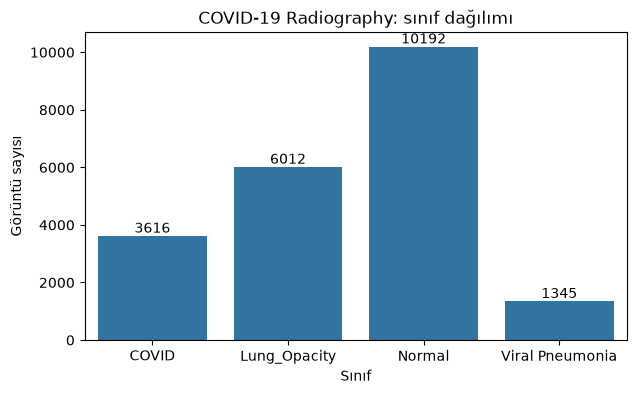

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 4))
sns.barplot(data=covid, x="Sınıf", y="Görüntü sayısı")
plt.title("COVID-19 Radiography: sınıf dağılımı")
for i, sayi in enumerate(covid["Görüntü sayısı"]):
    plt.text(i, sayi, str(sayi), ha="center", va="bottom")
plt.show()

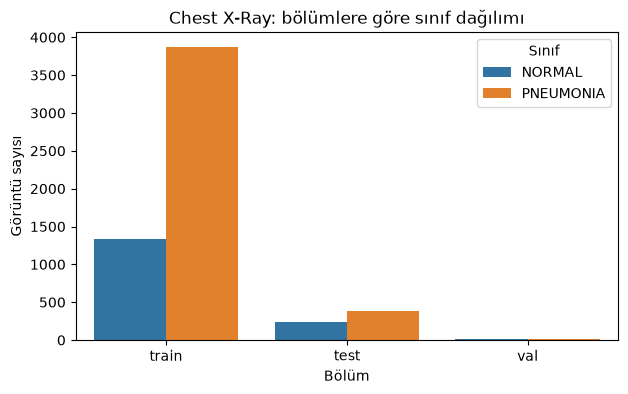

In [15]:
plt.figure(figsize=(7, 4))
sns.barplot(data=xray, x="Bölüm", y="Görüntü sayısı", hue="Sınıf")
plt.title("Chest X-Ray: bölümlere göre sınıf dağılımı")
plt.show()

In [18]:
from PIL import Image

kayit = []
for sinif in siniflar:
    for dosya in (ana / sinif / "images").glob("*.png"):
        with Image.open(dosya) as img:
            kayit.append([sinif, img.width, img.height, img.mode])

covid_boyut = pd.DataFrame(kayit, columns=["Sınıf", "Genişlik", "Yükseklik", "Mod"])
print(covid_boyut["Mod"].value_counts())
print(covid_boyut[["Genişlik", "Yükseklik"]].describe())

Mod
L      21025
RGB      140
Name: count, dtype: int64
       Genişlik  Yükseklik
count   21165.0    21165.0
mean      299.0      299.0
std         0.0        0.0
min       299.0      299.0
25%       299.0      299.0
50%       299.0      299.0
75%       299.0      299.0
max       299.0      299.0


In [19]:
kayit = []
for bolum in bolumler:
    for sinif in siniflar2:
        for dosya in (ana2 / bolum / sinif).glob("*.jpeg"):
            with Image.open(dosya) as img:
                kayit.append([bolum, sinif, img.width, img.height, img.mode])

xray_boyut = pd.DataFrame(kayit, columns=["Bölüm", "Sınıf", "Genişlik", "Yükseklik", "Mod"])
print(xray_boyut["Mod"].value_counts())
print(xray_boyut[["Genişlik", "Yükseklik"]].describe())

Mod
L      5573
RGB     283
Name: count, dtype: int64
          Genişlik    Yükseklik
count  5856.000000  5856.000000
mean   1327.880806   970.689037
std     363.500922   383.392117
min     384.000000   127.000000
25%    1056.000000   688.000000
50%    1281.000000   888.000000
75%    1560.000000  1187.000000
max    2916.000000  2713.000000


In [22]:
# Her iki veri setindeki tüm dosyaların sağlamlığını doğrulama
bozuk_dosyalar = []

# 1. COVID-19 Radiography kontrolü
for dosya in ana.rglob("*.png"):
    try:
        with Image.open(dosya) as img:
            img.verify()  # Dosya başlık ve yapısını kontrol eder
    except Exception as e:
        bozuk_dosyalar.append((str(dosya), str(e)))

# 2. Chest X-Ray kontrolü
for dosya in ana2.rglob("*.jpeg"):
    try:
        with Image.open(dosya) as img:
            img.verify()
    except Exception as e:
        bozuk_dosyalar.append((str(dosya), str(e)))

print(f"Toplam taranan dosya sayısı: {21165 + 5856}")
print(f"Bozuk/Okunamayan dosya sayısı: {len(bozuk_dosyalar)}")
if bozuk_dosyalar:
    print("Bozuk dosyalar:", bozuk_dosyalar[:5])
else:
    print("Tüm görüntüler sağlam, bozuk veya eksik dosya bulunamadı!")

Toplam taranan dosya sayısı: 27021
Bozuk/Okunamayan dosya sayısı: 0
Tüm görüntüler sağlam, bozuk veya eksik dosya bulunamadı!


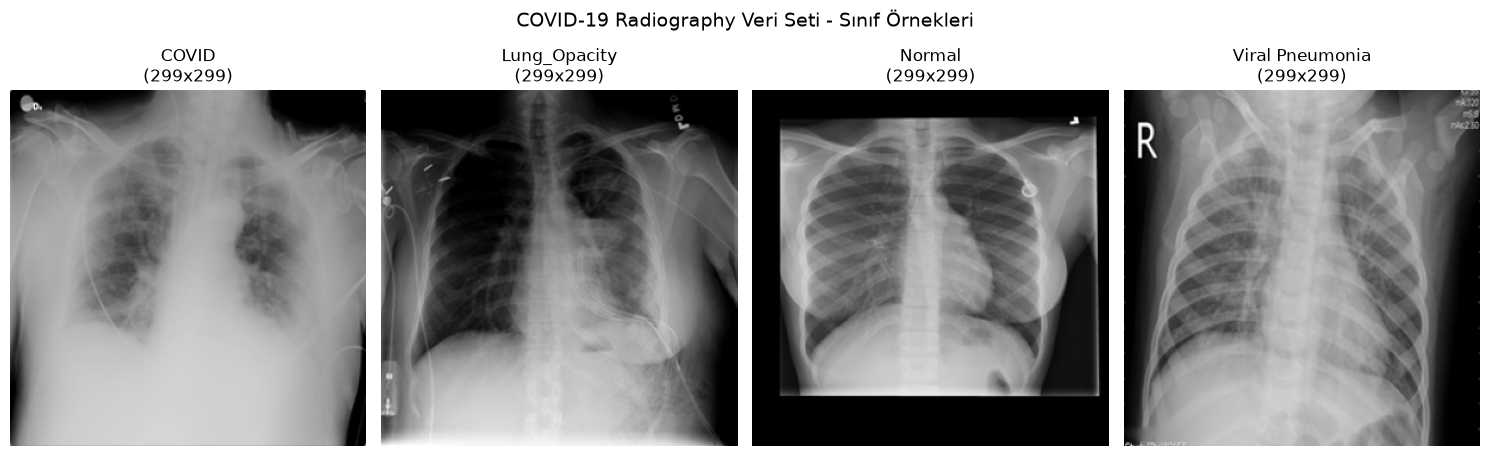

In [21]:
import matplotlib.pyplot as plt

# COVID-19 sınıflarından birer örnek görselleştirme
fig, axes = plt.subplots(1, len(siniflar), figsize=(15, 5))

for i, sinif in enumerate(siniflar):
    ornek_dosya = next((ana / sinif / "images").glob("*.png"))
    with Image.open(ornek_dosya) as img:
        axes[i].imshow(img, cmap="gray")
        axes[i].set_title(f"{sinif}\n(299x299)")
        axes[i].axis("off")

plt.suptitle("COVID-19 Radiography Veri Seti - Sınıf Örnekleri", fontsize=14)
plt.tight_layout()
plt.show()

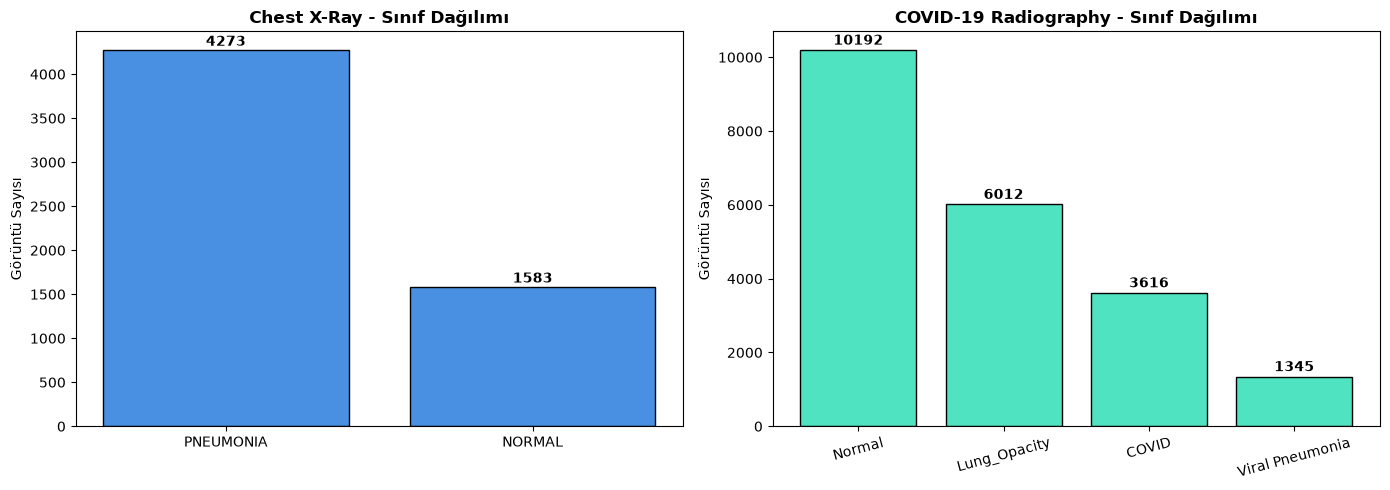

In [24]:
import matplotlib.pyplot as plt
from pathlib import Path

# Grafikleri kaydedeceğimiz klasörü oluşturalım
gorseller_yolu = Path("../gorseller")
gorseller_yolu.mkdir(exist_ok=True)

# İki veri setinin sınıf dağılımlarını yan yana çizdirme
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# 1. Chest X-Ray (Normal vs Pnömoni)
xray_sayilar = xray_boyut["Sınıf"].value_counts()
ax1.bar(xray_sayilar.index, xray_sayilar.values, color="#4A90E2", edgecolor="black")
ax1.set_title("Chest X-Ray - Sınıf Dağılımı", fontsize=12, fontweight="bold")
ax1.set_ylabel("Görüntü Sayısı")
for i, v in enumerate(xray_sayilar.values):
    ax1.text(i, v + 50, str(v), ha="center", fontweight="bold")

# 2. COVID-19 Radiography (4 Sınıf)
covid_sayilar = covid_boyut["Sınıf"].value_counts()
ax2.bar(covid_sayilar.index, covid_sayilar.values, color="#50E3C2", edgecolor="black")
ax2.set_title("COVID-19 Radiography - Sınıf Dağılımı", fontsize=12, fontweight="bold")
ax2.set_ylabel("Görüntü Sayısı")
ax2.tick_params(axis="x", rotation=15)
for i, v in enumerate(covid_sayilar.values):
    ax2.text(i, v + 150, str(v), ha="center", fontweight="bold")

plt.tight_layout()
plt.savefig(gorseller_yolu / "sinif_dagilimlari.png", dpi=300)
plt.show()

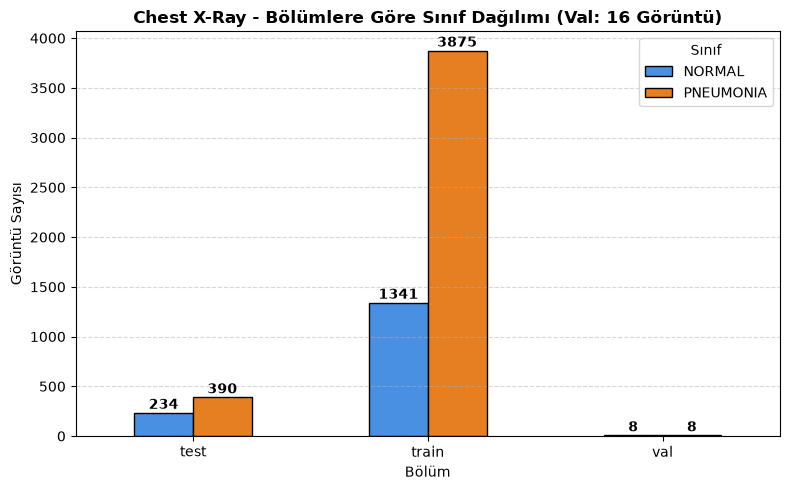

In [25]:
# Chest X-Ray train/val/test dağılımını gösteren grafik
bolum_sinif = xray_boyut.groupby(["Bölüm", "Sınıf"]).size().unstack()

ax = bolum_sinif.plot(kind="bar", figsize=(8, 5), color=["#4A90E2", "#E67E22"], edgecolor="black")
plt.title("Chest X-Ray - Bölümlere Göre Sınıf Dağılımı (Val: 16 Görüntü)", fontsize=12, fontweight="bold")
plt.ylabel("Görüntü Sayısı")
plt.xlabel("Bölüm")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.5)

# Çubukların üzerine sayıları yazdıralım
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f"{int(height)}", 
                    (p.get_x() + p.get_width() / 2., height + 40), 
                    ha="center", fontsize=10, fontweight="bold")

plt.tight_layout()
plt.savefig(gorseller_yolu / "bolum_dagilimi.png", dpi=300)
plt.show()

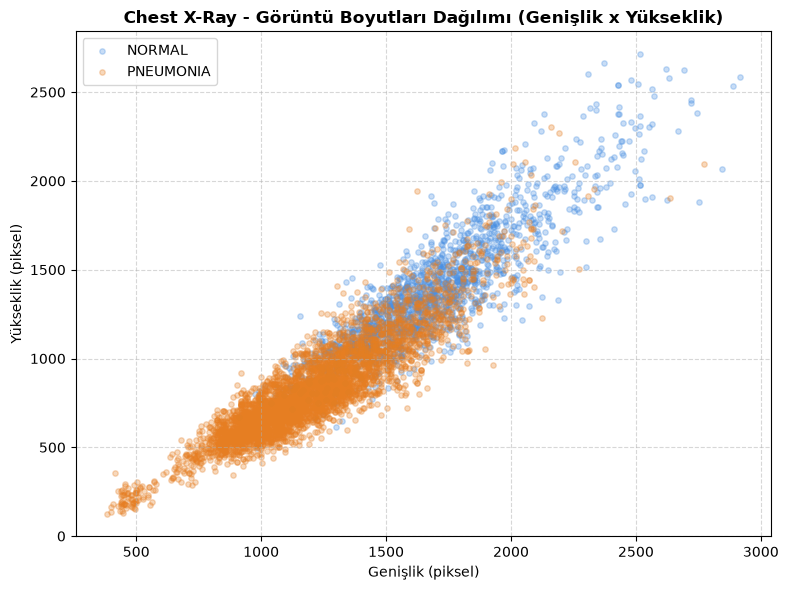

In [26]:
# Genişlik vs Yükseklik boyut dağılımı
plt.figure(figsize=(8, 6))

for sinif, renk in [("NORMAL", "#4A90E2"), ("PNEUMONIA", "#E67E22")]:
    alt = xray_boyut[xray_boyut["Sınıf"] == sinif]
    plt.scatter(alt["Genişlik"], alt["Yükseklik"], alpha=0.3, label=sinif, color=renk, s=15)

plt.title("Chest X-Ray - Görüntü Boyutları Dağılımı (Genişlik x Yükseklik)", fontsize=12, fontweight="bold")
plt.xlabel("Genişlik (piksel)")
plt.ylabel("Yükseklik (piksel)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig(gorseller_yolu / "boyut_dagilimi.png", dpi=300)
plt.show()

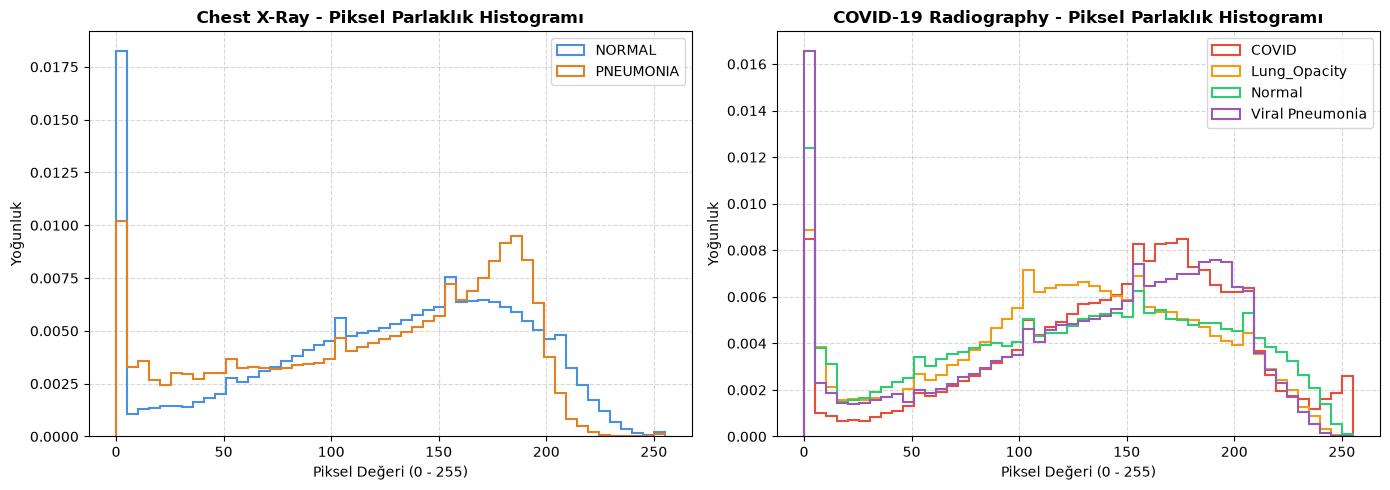

Bölüm 2.3 için gerekli tüm grafikler başarıyla oluşturuldu!


In [27]:
# Her sınıftan 50'şer görüntü örnekleyerek piksel yoğunluk histogramı çıkarma
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# 1. Chest X-Ray (Normal vs Pnömoni)
for sinif, renk in [("NORMAL", "#4A90E2"), ("PNEUMONIA", "#E67E22")]:
    pikseller = []
    dosyalar = list((ana2 / "train" / sinif).glob("*.jpeg"))[:50]
    for d in dosyalar:
        with Image.open(d) as img:
            pikseller.extend(np.array(img).flatten()[::10])  # Hızlı olması için örnekleme
    ax1.hist(pikseller, bins=50, density=True, histtype="step", linewidth=1.5, label=sinif, color=renk)

ax1.set_title("Chest X-Ray - Piksel Parlaklık Histogramı", fontsize=12, fontweight="bold")
ax1.set_xlabel("Piksel Değeri (0 - 255)")
ax1.set_ylabel("Yoğunluk")
ax1.legend()
ax1.grid(True, linestyle="--", alpha=0.5)

# 2. COVID-19 Radiography (4 Sınıf)
covid_renkler = {"COVID": "#E74C3C", "Normal": "#2ECC71", "Lung_Opacity": "#F39C12", "Viral Pneumonia": "#9B59B6"}
for sinif in siniflar:
    pikseller = []
    dosyalar = list((ana / sinif / "images").glob("*.png"))[:50]
    for d in dosyalar:
        with Image.open(d) as img:
            pikseller.extend(np.array(img).flatten()[::10])
    ax2.hist(pikseller, bins=50, density=True, histtype="step", linewidth=1.5, label=sinif, color=covid_renkler[sinif])

ax2.set_title("COVID-19 Radiography - Piksel Parlaklık Histogramı", fontsize=12, fontweight="bold")
ax2.set_xlabel("Piksel Değeri (0 - 255)")
ax2.set_ylabel("Yoğunluk")
ax2.legend()
ax2.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig(gorseller_yolu / "piksel_histogramlari.png", dpi=300)
plt.show()

print("Bölüm 2.3 için gerekli tüm grafikler başarıyla oluşturuldu!")